# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

Устройство Google Colab с Tesla T4  
Финальный прогон выполнен с FAST_MODE = False, обучение без CUDA запрещено проверкой устройства

Модель [BERT Tiny](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2), лицензия Apache 2  
Датасет [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), английские сплиты, лицензия CC BY-NC-SA 4  
Фиксированная выборка из большого корпуса содержит 10000 / 2000 / 2000 предложений  
Бонусы на сдвиг текста, квантизацию и порог уверенности

Источники [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), [BERT Tiny](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2), [Transformers](https://huggingface.co/docs/transformers/main/en/tasks/token_classification), [seqeval](https://github.com/chakki-works/seqeval), [PyTorch](https://docs.pytorch.org/docs/stable/quantization-support.html)  
При подготовке кода и проверке использован Codex

Версии среды приведены в файле analysis из каталога artifacts  
Данные и веса скачиваются кодом, в сдачу не включены

Выполнены все обязательные задачи и три выбранных бонуса, доразметка и вторая модель не выбраны  


In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q --no-cache-dir --disable-pip-version-check "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
# одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ.setdefault('HF_HOME', os.path.abspath('data/hf_cache'))
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
from torch.utils.data import DataLoader
from seqeval.metrics.sequence_labeling import get_entities
import platform
import warnings

torch.set_num_threads(min(4, os.cpu_count() or 1))


torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else f'{device.type} {platform.machine()}'
set_seed(0)
print(device, DEVICE_NAME)


cuda Tesla T4


In [4]:
# True - отладка, False - финальный прогон
# например {'6.3', '6.5'}; пустое множество отключает все бонусы
# None - весь train
# подмножество validation и test в FAST_MODE
# длина в сабвордах, длиннее - обрезается
FAST_MODE = False
BONUS_TASKS = {'6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None
N_EVAL = 500 if FAST_MODE else None
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
# для roberta-base: {'add_prefix_space': True}
MODEL_ID = 'google/bert_uncased_L-2_H-128_A-2'
REVISION = '30b0a37ccaaa32f332884b96992754e246e48c5f'
TOKENIZER_KWARGS = {'use_fast': True, 'do_lower_case': True}


In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google/bert_uncased_L-2_H-128_A-2
revision: 30b0a37ccaaa32f332884b96992754e246e48c5f
license:  apache-2.0
language: None
updated:  2023-09-05 15:25:24+00:00
weights:  {'model.safetensors': '17 MB', 'pytorch_model.bin': '17 MB'}


config.json:   0%|          | 0.00/382 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

BertTokenizer vocab size 30522
['п', '##е', '##т', '##р', 'и', '##л', '##ь', '##и', '##ч', 'ч', '##а', '##и', '##к', '##ов', '##с', '##к', '##ии', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'в', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

BERT Tiny подходит английскому WikiNEuRal и позволяет быстро обучаться благодаря двум слоям и hidden size 128  
Это базовый энкодер с WordPiece, предобученный по рецепту BERT на английских текстах, включая Wikipedia и BooksCorpus, а не готовая NER-модель  
Лицензия модели: Apache 2.0

[bert-base-cased](https://huggingface.co/google-bert/bert-base-cased) содержит около 108 млн параметров, сохраняет регистр и имеет 12 слоев, поэтому ожидается лучшее качество NER ценой большего числа параметров и вычислений  
[DistilmBERT](https://huggingface.co/distilbert/distilbert-base-multilingual-cased) содержит 134 млн параметров, 6 слоев и обучен на Wikipedia для 104 языков, его карточка сообщает двукратное ускорение относительно mBERT, но это не измерение относительно Tiny  
В карточке Tiny приведен GLUE 64,2, прямого сравнения NER для этих моделей там нет, поэтому превосходство на моих данных требует отдельного эксперимента

Полный commit hash фиксирует веса, конфигурацию и словарь, без него обновление main может изменить сабворды, выравнивание и результаты, при этом версии библиотек фиксируются отдельно  


## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B / 17.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 30522, 'hidden_size': 128, 'num_hidden_layers': 2, 'num_attention_heads': 2, 'intermediate_size': 512, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
# -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
def params_by_block(model):
    base = model.base_model
    embeddings = {id(p) for p in base.embeddings.parameters()}
    if hasattr(base, 'encoder') and hasattr(base.encoder, 'layer'):
        layers = list(base.encoder.layer)
    elif hasattr(base, 'transformer') and hasattr(base.transformer, 'layer'):
        layers = list(base.transformer.layer)
    else:
        raise ValueError('Не найдены слои энкодера')
    layer_ids = [{id(p) for p in layer.parameters()} for layer in layers]
    encoder = set().union(*layer_ids) if layer_ids else set()
    head = {id(p) for p in model.classifier.parameters()}
    groups = {'embeddings': embeddings, 'encoder': encoder, 'head': head}
    assert not (embeddings & encoder or embeddings & head or encoder & head)
    parameters = {id(p): p.numel() for p in model.parameters()}
    result = {name: sum(parameters[p] for p in ids) for name, ids in groups.items()}
    result['other'] = sum(n for p, n in parameters.items() if p not in embeddings | encoder | head)
    result['layers'] = [sum(parameters[p] for p in ids) for ids in layer_ids]
    return result


In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings     3,972,864   90.9%
encoder          396,544    9.1%
head                 903    0.0%
other                  0    0.0%
total          4,370,311
per layer: [198272, 198272]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
print('hidden_states', [tuple(h.shape) for h in out.hidden_states])
print('logits', tuple(out.logits.shape))


input_ids (2, 32)
attention_mask (2, 32)
hidden_states [(2, 32, 128), (2, 32, 128), (2, 32, 128)]
logits (2, 32, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 7.0 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

В демонстрационном батче input_ids и attention_mask имеют форму [2, 32]  
Эмбеддинги и выходы двух слоев энкодера дают три hidden_states формы [2, 32, 128], а линейная голова дает logits [2, 32, 7]

Больше всего параметров у эмбеддингов, 3972864 из 4370311, то есть 90,9%, поскольку словарь содержит 30522 строки по 128 значений  
Энкодер содержит 396544 параметров, голова на семь демонстрационных тегов содержит 903  
Токены обмениваются контекстом в слоях энкодера, таблица эмбеддингов и линейная голова применяются к каждой позиции отдельно  
Длина T определяется сабвордами и специальными токенами, а padding выравнивает два предложения по длине, поэтому T может превышать число слов  


---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [36]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
DATASET_LANGUAGE = 'en'
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
files = {name: f'hf://datasets/{DATASET_ID}@{DATASET_REVISION}/data/{source}_en-00000-of-00001.parquet'
         for name, source in [('train', 'train'), ('validation', 'val'), ('test', 'test')]}
source_data = load_dataset('parquet', data_files=files)
source_sizes = {name: len(ds) for name, ds in source_data.items()}
limits = {'train': 10000, 'validation': 2000, 'test': 2000}
seen = set()
selected, duplicate_counts = {}, {}
for name in ['train', 'validation', 'test']:
    indices, duplicates = [], 0
    shuffled = source_data[name].shuffle(seed=SEED)
    for i, ex in enumerate(shuffled):
        key = tuple(ex['tokens'])
        if key in seen:
            duplicates += 1
            continue
        seen.add(key)
        indices.append(i)
        if len(indices) == limits[name]:
            break
    selected[name] = shuffled.select(indices).select_columns(['tokens', 'ner_tags'])
    duplicate_counts[name] = duplicates
raw = DatasetDict(selected)
assert all(len(ex['tokens']) == len(ex['ner_tags']) for ds in raw.values() for ex in ds)
print('Исходные размеры', source_sizes)
print('Исключенные повторы при отборе', duplicate_counts)
print(raw)
for ex in raw['train'].select(range(3)):
    print(list(zip(ex['tokens'], [LABEL_NAMES[i] for i in ex['ner_tags']])))


data/train_en-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.18MB            

data/train_en-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/val_en-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  899kB            

data/val_en-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test_en-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  894kB            

data/test_en-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Исходные размеры {'train': 92720, 'validation': 11590, 'test': 11597}
Исключенные повторы при отборе {'train': 0, 'validation': 0, 'test': 0}
DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
})
[('This', 'O'), ('growth', 'O'), ('and', 'O'), ('its', 'O'), ('high', 'O'), ('use', 'O'), ('of', 'O'), ('recruitment', 'O'), ('agencies', 'O'), ('to', 'O'), ('hire', 'O'), ('graduates', 'O'), ('as', 'O'), ('temporary', 'O'), ('workers', 'O'), ('has', 'O'), ('led', 'O'), ('to', 'O'), ('accusations', 'O'), ('of', 'O'), ('exploitative', 'O'), ('practices', 'O'), ('such', 'O'), ('as', 'O'), ('long', 'O'), ('hours', 'O'), (',', 'O'), ('poor', 'O'), ('pay', 'O'), ('and', 'O'), ('lack', 'O'), ('of', 'O'), ('job', 'O'), ('security', 'O'), ('by', 'O'), ('the',

train {"sentences": 10000, "entities": {"ORG": 2598, "MISC": 4268, "PER": 4366, "LOC": 5997}, "mean_span_length": 1.5896453653723372, "mean_sentence_length": 23.5428, "max_sentence_length": 133, "span_p95": 3.0, "sentence_p95": 45.0}
validation {"sentences": 2000, "entities": {"PER": 1017, "LOC": 975, "MISC": 843, "ORG": 598}, "mean_span_length": 1.7011360326245266, "mean_sentence_length": 23.519, "max_sentence_length": 85, "span_p95": 3.0, "sentence_p95": 44.0}
test {"sentences": 2000, "entities": {"MISC": 905, "PER": 850, "LOC": 1017, "ORG": 588}, "mean_span_length": 1.6416666666666666, "mean_sentence_length": 23.029, "max_sentence_length": 93, "span_p95": 3.0, "sentence_p95": 45.0}


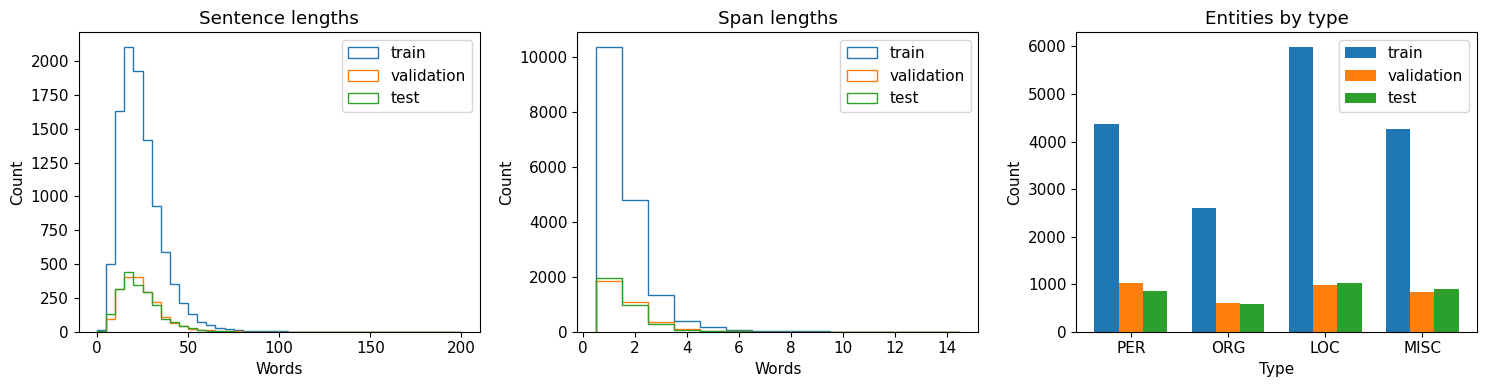

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
dataset_stats = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for split, ds in raw.items():
    counts, span_lengths, sentence_lengths = collections.Counter(), [], []
    for ex in ds:
        entities = get_entities([LABEL_NAMES[i] for i in ex['ner_tags']])
        counts.update(t for t, _, _ in entities)
        span_lengths.extend(end - start + 1 for _, start, end in entities)
        sentence_lengths.append(len(ex['tokens']))
    dataset_stats[split] = dict(sentences=len(ds), entities=dict(counts),
                               mean_span_length=float(np.mean(span_lengths)),
                               mean_sentence_length=float(np.mean(sentence_lengths)),
                               max_sentence_length=max(sentence_lengths),
                               span_p95=float(np.percentile(span_lengths, 95)),
                               sentence_p95=float(np.percentile(sentence_lengths, 95)))
    print(split, json.dumps(dataset_stats[split], ensure_ascii=False))
    axes[0].hist(sentence_lengths, bins=range(0, 201, 5), histtype='step', label=split)
    axes[1].hist(span_lengths, bins=np.arange(0.5, 15.5, 1), histtype='step', label=split)
types = ['PER', 'ORG', 'LOC', 'MISC']
x_pos = np.arange(len(types))
for j, (split, stats) in enumerate(dataset_stats.items()):
    axes[2].bar(x_pos + (j - 1) * 0.25, [stats['entities'].get(t, 0) for t in types], 0.25, label=split)
axes[2].set_xticks(x_pos, types)
for ax, title, xlabel in zip(axes, ['Sentence lengths', 'Span lengths', 'Entities by type'], ['Words', 'Words', 'Type']):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Count')
    ax.legend()
plt.tight_layout()
plt.show()


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

Выбран [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), английские предложения из Wikipedia с автоматически полученной silver-разметкой на основе BabelNet и нейронных моделей  
Лицензия датасета: CC BY-NC-SA 4.0  
Исходные английские сплиты содержат 92720 / 11590 / 11597 предложений, для ограниченного бюджета отобраны фиксированные подмножества с seed 0

train: 10000 предложений, PER 4366, ORG 2598, LOC 5997, MISC 4268  
validation: 2000 предложений, PER 1017, ORG 598, LOC 975, MISC 843  
test: 2000 предложений, PER 850, ORG 588, LOC 1017, MISC 905

Самый редкий тип в train это ORG  
Средняя длина спана в train составляет 1,59 слова, 95-й процентиль 3, средняя длина предложения 23,54 слова, 95-й процентиль 45  
Длинные сущности могут обрезаться при токенизации, а автоматическая разметка содержит потенциальные пропуски и неоднозначные типы  
Точные повторы исключены внутри выбранных данных и между сплитами, но близкие фразы из одной статьи могут сохраняться  


## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
# ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
# [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
# word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
def bio_to_spans(tags):
    spans = []
    start, entity_type = None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, current_type = 'O', None
        else:
            prefix, sep, current_type = tag.partition('-')
            if prefix not in {'B', 'I'} or not sep or not current_type:
                raise ValueError(f'Некорректный BIO-тег {tag}')
        continues = prefix == 'I' and start is not None and current_type == entity_type
        if start is not None and not continues:
            spans.append((start, i, entity_type))
            start, entity_type = None, None
        if prefix != 'O' and not continues:
            start, entity_type = i, current_type
    return spans


def spans_to_bio(spans, n_words):
    if not isinstance(n_words, int) or n_words < 0:
        raise ValueError('Длина должна быть неотрицательным целым числом')
    tags = ['O'] * n_words
    for start, end, entity_type in sorted(spans):
        if not 0 <= start < end <= n_words or not entity_type:
            raise ValueError('Некорректные границы или тип спана')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError('Пересекающиеся спаны не представимы одним BIO-слоем')
        tags[start] = 'B-' + entity_type
        tags[start + 1:end] = ['I-' + entity_type] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    result, seen = [], set()
    for word_id in word_ids:
        if word_id is None:
            result.append(-100)
            continue
        if not 0 <= word_id < len(word_labels):
            raise ValueError('Номер слова вне разметки')
        label = int(word_labels[word_id])
        if word_id not in seen:
            result.append(label)
        elif b_to_i is None:
            result.append(-100)
        else:
            result.append(b_to_i.get(label, label))
        seen.add(word_id)
    return result


In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
roundtrip_stats = {}
for split, ds in raw.items():
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}, ensure_ascii=False) + '\n')
    changed = 0
    with path.open(encoding='utf-8') as f:
        restored = [json.loads(line) for line in f]
    assert len(restored) == len(ds)
    for original, saved in zip(ds, restored):
        tags = [LABEL_NAMES[i] for i in original['ner_tags']]
        saved_spans = [tuple(s) for s in saved['spans']]
        back = spans_to_bio(saved_spans, len(saved['tokens']))
        assert saved['tokens'] == original['tokens']
        assert bio_to_spans(back) == bio_to_spans(tags) == saved_spans
        changed += back != tags
    roundtrip_stats[split] = {'checked': len(ds), 'noncanonical_bio': changed}
    print(split, roundtrip_stats[split])
    print(restored[0])
for tags in [['I-PER', 'I-ORG', 'O'], ['B-art-film', 'I-art-film'], ['B-LOC', 'B-LOC']]:
    assert bio_to_spans(tags) == [(start, end + 1, typ) for typ, start, end in get_entities(tags)]
try:
    spans_to_bio([(0, 2, 'PER'), (1, 3, 'ORG')], 3)
except ValueError:
    pass
else:
    raise AssertionError('Нужно отклонять пересечения')
print('Конвертация и дополнительные проверки пройдены')


train {'checked': 10000, 'noncanonical_bio': 289}
{'tokens': ['This', 'growth', 'and', 'its', 'high', 'use', 'of', 'recruitment', 'agencies', 'to', 'hire', 'graduates', 'as', 'temporary', 'workers', 'has', 'led', 'to', 'accusations', 'of', 'exploitative', 'practices', 'such', 'as', 'long', 'hours', ',', 'poor', 'pay', 'and', 'lack', 'of', 'job', 'security', 'by', 'the', 'TUC', 'and', 'other', 'union', 'bodies', '.'], 'spans': [[36, 37, 'ORG']]}
validation {'checked': 2000, 'noncanonical_bio': 56}
{'tokens': ['Interactions', 'between', 'the', 'components', 'of', 'the', 'solution', 'create', 'properties', 'unique', 'to', 'the', 'solution', ',', 'as', 'most', 'processes', 'entail', 'nonideal', 'mixtures', ',', 'where', 'Raoult', "'s", 'law', 'does', 'not', 'hold', '.'], 'spans': [[22, 23, 'PER']]}
test {'checked': 2000, 'noncanonical_bio': 51}
{'tokens': ['The', 'Japanese', 'idiom', '"', 'tanin', 'no', 'fundoshi', '"', '(', 'literally', ',', '"', 'anyone', 'else', "'s", 'fundoshi', '"', '

In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')
coverage_stats = {}
for split, ds in data.items():
    audit = {'sentences_truncated': 0, 'words_lost': 0, 'words_without_subwords': 0}
    for offset in range(0, len(ds), 256):
        rows = ds[offset:offset + 256]['tokens']
        full_enc = tokenizer(rows, is_split_into_words=True, truncation=False)
        cut_enc = tokenizer(rows, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
        for j, words in enumerate(rows):
            full_ids = set(full_enc.word_ids(j)) - {None}
            cut_ids = set(cut_enc.word_ids(j)) - {None}
            audit['sentences_truncated'] += len(full_enc['input_ids'][j]) > MAX_LENGTH
            audit['words_lost'] += len(words) - len(cut_ids)
            audit['words_without_subwords'] += len(words) - len(full_ids)
    coverage_stats[split] = audit
print('Проверка покрытия', coverage_stats)


Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 9997 предложений, обрезано по MAX_LENGTH 4, слов без сабвордов или за обрезкой 32
[CLS]            None  -100
this                0  O
growth              1  O
and                 2  O
its                 3  O
high                4  O
use                 5  O
of                  6  O
recruitment         7  O
agencies            8  O
to                  9  O
hire               10  O
graduates          11  O
as                 12  O
temporary          13  O
workers            14  O
has                15  O
led                16  O
to                 17  O
accusations        18  O
of                 19  O
exploit            20  O
##at

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Первый сабворд представляет слово при обучении и оценке, а остальные части не создают повторный вклад длинных слов в loss  
Значение -100 является ignore_index в cross-entropy, поэтому специальные токены, padding и продолжения слов не влияют на градиент

В train обрезано 3 предложений и потеряно 32 слов, в validation 0 и 0, в test 0 и 0  
Слов без сабвордов до обрезки найдено 0 по трем сплитам  
Выпавшие слова при предсказании получают O, поэтому сущности на хвостах могут стать пропусками или ошибками границ  
На validation и test обрезки нет, поэтому в текущей оценке этого источника ошибок не возникло

После экспорта BIO в JSON-спаны и обратного чтения совпали все спаны в 14000 предложениях  
Неканоническая BIO-последовательность найдена в 396 предложениях, пересекающихся и вложенных спанов в выбранном однослойном формате нет  
Синтетические тесты отдельно проверяют I без B, смену типа после I, дефисы в типе и отклонение пересечений  


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
# -> dict: слово -> самый частый тег этого слова в train
# -> список тегов той же длины; незнакомое слово -> 'O'
def fit_majority_tagger(tokens_list, tags_list):
    if len(tokens_list) != len(tags_list):
        raise ValueError('Число предложений не совпадает')
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        if len(words) != len(tags):
            raise ValueError('Число слов и меток не совпадает')
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: counter.most_common(1)[0][0] for word, counter in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]


In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(majority_tagger, words) for words in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {'majority': entity_scores(val_gold, majority_pred),
            'random_head': entity_scores(val_gold, random_pred)}
random_tag_counts = dict(collections.Counter(t for tags in random_pred for t in tags))
unknown_words = sum(w not in majority_tagger for words in val_tokens for w in words)
unknown_fraction = unknown_words / sum(map(len, val_tokens))
print(json.dumps(baseline, ensure_ascii=False, indent=2))
print('Теги случайной головы', random_tag_counts)
print('Доля незнакомых слов', unknown_fraction)
del random_model


Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

{
  "majority": {
    "f1_micro": 0.36879000304785126,
    "f1_macro": 0.3652377680488791,
    "precision": 0.3867050175775008,
    "recall": 0.35246140401980774
  },
  "random_head": {
    "f1_micro": 0.011440245148110316,
    "f1_macro": 0.011197083955725426,
    "precision": 0.00665335994677312,
    "recall": 0.040780658316341395
  }
}
Теги случайной головы {'I-MISC': 20198, 'I-LOC': 9768, 'O': 10589, 'B-PER': 3165, 'B-MISC': 858, 'I-ORG': 333, 'I-PER': 995, 'B-LOC': 899, 'B-ORG': 233}
Доля незнакомых слов 0.08295420723670224


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

На validation словарный бейзлайн получил F1 0,369, случайная голова 0,011  
Словарь использует повторяющиеся имена из train, однако доля незнакомых слов равна 8,3%, контекст и новые сочетания известных слов он не учитывает  
Даже правильные теги отдельных слов могут давать неверные границы сущностей

У случайной головы нет обученного соответствия между векторами энкодера и BIO-тегами, поэтому языковое предобучение само по себе не решает NER  
Чаще всего она предсказывает I-MISC, полное распределение выведено в ячейке  
Низкий F1 обусловлен случайными типами и границами, а не отсутствием информации в энкодере  


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
# подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
# уменьшите, если не влезает в память T4
# -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    if device.type != 'cuda':
        raise RuntimeError('Для обучения включите GPU в Google Colab')
    tok = tok or tokenizer
    set_seed(SEED)
    model.requires_grad_(True)
    if freeze_encoder:
        model.base_model.requires_grad_(False)
    model.to(device)
    collator = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if device.type == 'cuda' else None)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=generator,
                              collate_fn=collator, num_workers=0)
    eval_loader = DataLoader(eval_ds, batch_size=batch_size * 2, shuffle=False,
                             collate_fn=collator, num_workers=0)
    decay, no_decay = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (no_decay if parameter.ndim == 1 or name.endswith('.bias') else decay).append(parameter)
    optimizer = torch.optim.AdamW([{'params': decay, 'weight_decay': 0.01},
                                   {'params': no_decay, 'weight_decay': 0.0}], lr=lr)
    total_steps = math.ceil(len(train_loader) * epochs)
    warmup_steps = max(1, int(total_steps * 0.1))
    def lr_factor(step):
        if step < warmup_steps:
            return step / warmup_steps
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    log_every = max(1, total_steps // 10)
    history, step, loss_sum, word_count = [], 0, 0.0, 0
    def sync():
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elif device.type == 'mps':
            torch.mps.synchronize()
    sync()
    start = time.perf_counter()
    optimizer.zero_grad(set_to_none=True)
    for epoch in range(math.ceil(epochs)):
        for batch in train_loader:
            if step >= total_steps:
                break
            model.train()
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise RuntimeError('Получен нечисловой loss')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            count = int((batch['labels'] != -100).sum())
            loss_sum += float(loss.detach()) * count
            word_count += count
            step += 1
            if step % log_every == 0 or step == total_steps:
                history.append({'step': step, 'loss': loss_sum / max(1, word_count),
                                'learning_rate': scheduler.get_last_lr()[0]})
                model.eval()
                eval_sum, eval_count = 0.0, 0
                with torch.no_grad():
                    for eval_batch in eval_loader:
                        eval_batch = {k: v.to(device) for k, v in eval_batch.items()}
                        count = int((eval_batch['labels'] != -100).sum())
                        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
                            eval_loss = model(**eval_batch).loss
                        eval_sum += float(eval_loss) * count
                        eval_count += count
                value = eval_sum / max(1, eval_count)
                history.append({'step': step, 'eval_loss': value})
                print(f'step {step}/{total_steps} train {history[-2]["loss"]:.4f} validation {value:.4f}', flush=True)
                loss_sum, word_count = 0.0, 0
    sync()
    seconds = time.perf_counter() - start
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    Path(out_dir, 'history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    model.eval()
    return history, seconds


Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

/tmp/ipykernel_562/1547127858.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


step 93/939 train 1.0397 validation 0.4845
step 186/939 train 0.3561 validation 0.2933
step 279/939 train 0.2681 validation 0.2224
step 372/939 train 0.2105 validation 0.1927
step 465/939 train 0.1937 validation 0.1796
step 558/939 train 0.1814 validation 0.1708
step 651/939 train 0.1586 validation 0.1641
step 744/939 train 0.1444 validation 0.1617
step 837/939 train 0.1456 validation 0.1598
step 930/939 train 0.1376 validation 0.1585
step 939/939 train 0.1448 validation 0.1585
обучение: 20.2 c на Tesla T4, 10000 предложений, 3 эпох(а)


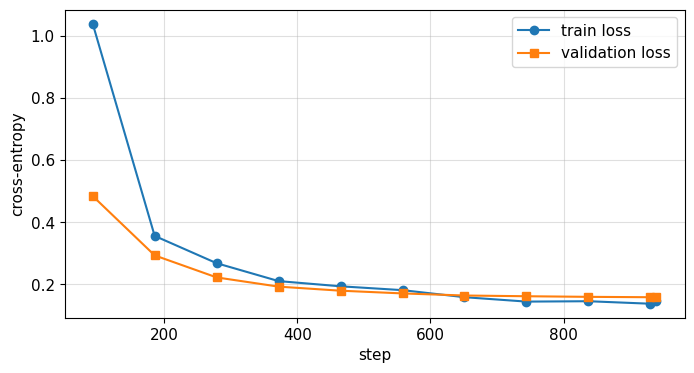

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Для маленького BERT выбран learning rate 0,0002, batch size 32 и три эпохи, этого достаточно для сотен обновлений при выбранном вычислительном бюджете  
Линейный warmup занимает 10% шагов, далее learning rate линейно снижается до нуля, AdamW использует weight decay 0,01 без decay для bias и одномерных параметров  
Gradient clipping ограничен значением 1, padding динамический, fp16 включается только на CUDA, в этом облачном прогоне используется CUDA и fp16

Train loss снизился с 1,040 до 0,145, validation loss с 0,485 до 0,159, оценка выполнена 11 раз  
Сильного роста validation loss к концу нет, явного переобучения по этой кривой не видно, пользу дополнительных эпох нужно проверять на validation  
Обучение вместе с промежуточными оценками заняло 20,2 секунды на Tesla T4

В начале сохраненного AMP-прогона есть предупреждение scheduler, GradScaler может пропустить обновление при переполнении, поэтому в следующем эксперименте стоит привязать шаг scheduler к фактически выполненному шагу оптимизатора  


## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
# gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
def token_f1(gold, pred):
    if len(gold) != len(pred) or any(len(g) != len(p) for g, p in zip(gold, pred)):
        raise ValueError('Размеры разметки не совпадают')
    tp = predicted = actual = 0
    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            tp += g == p and g != 'O'
            predicted += p != 'O'
            actual += g != 'O'
    return 2 * tp / (predicted + actual) if predicted + actual else 0.0


In [25]:
# предсказанные теги validation (список списков), нужны в 5.1
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def evaluate_tags(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    result = entity_scores(gold, pred)
    result['token_f1'] = token_f1(gold, pred)
    result['per_type'] = {typ: report[typ] for typ in ENTITY_TYPES}
    return result

val_pred = predict_word_tags(model, val_tokens)
validation = evaluate_tags(val_gold, val_pred)
test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = evaluate_tags(test_gold, test_pred)
for name, gold, pred, scores in [('validation', val_gold, val_pred, validation), ('test', test_gold, test_pred, final)]:
    print(name)
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print(json.dumps({k: v for k, v in scores.items() if k != 'per_type'}, ensure_ascii=False, indent=2))


validation
              precision    recall  f1-score   support

         LOC     0.6543    0.7436    0.6961       975
        MISC     0.4731    0.4389    0.4554       843
         ORG     0.5091    0.5134    0.5112       598
         PER     0.7747    0.8181    0.7958      1017

   micro avg     0.6263    0.6507    0.6383      3433
   macro avg     0.6028    0.6285    0.6146      3433
weighted avg     0.6202    0.6507    0.6343      3433

{
  "f1_micro": 0.6382857142857142,
  "f1_macro": 0.6146320283344249,
  "precision": 0.6262966077936641,
  "recall": 0.6507427905621905,
  "token_f1": 0.7265240354489303
}
test
              precision    recall  f1-score   support

         LOC     0.6910    0.7542    0.7212      1017
        MISC     0.5341    0.4851    0.5084       905
         ORG     0.5407    0.5425    0.5416       588
         PER     0.7539    0.7965    0.7746       850

   micro avg     0.6439    0.6554    0.6496      3360
   macro avg     0.6299    0.6446    0.6364      33

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

На validation micro-F1 равен 0,638, на test 0,650, test macro-F1 равен 0,636  
Хуже всего на test распознается MISC, F1 0,508 при support 905  
У MISC на test 905 примеров против 588 у ORG, поэтому слабое качество нельзя объяснить только редкостью, этот тип объединяет разнородные национальности, события и названия произведений

Micro объединяет TP, FP и FN всех типов, macro одинаково взвешивает F1 четырех типов, поэтому разница отражает неодинаковое качество между классами  
Токенный F1 равен 0,732 и выше F1 по сущностям 0,650, поскольку частично правильный спан может сохранять верно размеченные слова, но не засчитывается как точная сущность  
Для пользователя, извлекающего имена целиком с правильным типом, ближе F1 по сущностям  


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
# -> [(категория, gold-спан или None, pred-спан или None), ...]
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    result = []
    def overlap(gold, pred):
        return max(0, min(gold[1], pred[1]) - max(gold[0], pred[0]))
    for gold in gold_spans:
        exact = [p for p in pred_spans if tuple(p) == tuple(gold)]
        intersecting = [p for p in pred_spans if overlap(gold, p)]
        same_type = [p for p in intersecting if p[2] == gold[2]]
        if exact:
            result.append(('correct', gold, exact[0]))
        elif same_type:
            best = max(same_type, key=lambda p: (overlap(gold, p), -abs(p[0] - gold[0]) - abs(p[1] - gold[1])))
            result.append(('boundary', gold, best))
        elif intersecting:
            best = max(intersecting, key=lambda p: overlap(gold, p))
            result.append(('type', gold, best))
        else:
            result.append(('missed', gold, None))
    for pred in pred_spans:
        if not any(overlap(gold, pred) for gold in gold_spans):
            result.append(('spurious', None, pred))
    return result


In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

error_counter = collections.Counter({category: 0 for category in ERROR_CATEGORIES})
error_examples = {category: [] for category in ERROR_CATEGORIES if category != 'correct'}
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        error_counter[category] += 1
        if category != 'correct' and len(error_examples[category]) < 2:
            error_examples[category].append({'tokens': words, 'gold': gold_span, 'pred': pred_span})
errors = dict(error_counter)
error_total = sum(count for category, count in errors.items() if category != 'correct')
print('Категории', errors)
print('Доли среди ошибок', {category: round(count / error_total, 4) for category, count in errors.items() if category != 'correct'})
for category, examples in error_examples.items():
    for example in examples:
        def show_span(span):
            return None if span is None else (span, ' '.join(example['tokens'][span[0]:span[1]]))
        print('\n', category)
        print(' '.join(example['tokens']))
        print('gold', show_span(example['gold']))
        print('pred', show_span(example['pred']))
assert sum(map(len, error_examples.values())) >= 5


Категории {'correct': 2234, 'boundary': 370, 'type': 421, 'missed': 408, 'spurious': 349}
Доли среди ошибок {'boundary': 0.239, 'type': 0.272, 'missed': 0.2636, 'spurious': 0.2255}

 boundary
The album 's two singles were " Unbreakable " , which reached the top ten of the " Billboard " Hot R&B / Hip-Hop chart , and " Every Little Bit Hurts " , which failed to enter the US and international charts .
gold ((20, 24, 'MISC'), 'Hot R&B / Hip-Hop')
pred ((20, 22, 'MISC'), 'Hot R&B')

 boundary
Her poems were admired by prominent Indian politicians like Gopal Krishna Gokhale .
gold ((9, 12, 'PER'), 'Gopal Krishna Gokhale')
pred ((10, 12, 'PER'), 'Krishna Gokhale')

 type
The album 's two singles were " Unbreakable " , which reached the top ten of the " Billboard " Hot R&B / Hip-Hop chart , and " Every Little Bit Hurts " , which failed to enter the US and international charts .
gold ((18, 19, 'ORG'), 'Billboard')
pred ((18, 19, 'MISC'), 'Billboard')

 type
In 2011 , the Peabody Essex Museum an

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Чаще всего встречается категория type, 421 случаев, или 27,2% от всех категорий ошибок на validation  
Получено 370 ошибок границ, 421 ошибок типа, 408 пропусков и 349 лишних спанов, верных спанов 2234  
В ячейке показаны по два реальных примера каждой найденной категории с текстом и обеими разметками

В ошибках границ Hot R&B / Hip-Hop сокращается до Hot R&B, а имя Gopal Krishna Gokhale до Krishna Gokhale, то есть модель узнает только часть длинного имени  
При ошибках типа Billboard перепутан с MISC вместо ORG, а Peabody Essex Museum с ORG вместо LOC, здесь важны контекст и соглашение о типах  
Tetris пропущен целиком, в лишних спанах есть обычное сочетание war service, поэтому нужны и примеры редких названий, и трудные отрицательные примеры  
Peabody Essex Museum размечен как LOC, хотя в предложении музей объявляет о сборе средств как организация, это кандидат на контекстную ошибку silver-разметки, но окончательный вывод требует инструкции по различению здания и учреждения  
Для сокращения самой частой категории type я бы проверил спорные метки, добавил контекстные примеры различения ORG, PER и LOC и сравнил энкодер с сохранением регистра  
Категоризация следует условию и может сопоставлять один предсказанный спан нескольким истинным, поэтому ее суммы не заменяют TP, FP и FN из seqeval  


## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
# 'freeze' или 'all_subwords'
ABLATION = 'freeze'
set_seed(SEED)
ablation_model = make_model()
ablation_history, ablation_seconds = train_ner(ablation_model, tokenized['train'], tokenized['validation'],
                                               freeze_encoder=True, out_dir='runs/freeze')
ablation_pred = predict_word_tags(ablation_model, val_tokens)
ablation = {'setting': ABLATION, 'split': 'validation',
            'full': {'metrics': entity_scores(val_gold, val_pred), 'time_sec': train_seconds,
                     'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad)},
            'freeze': {'metrics': entity_scores(val_gold, ablation_pred), 'time_sec': ablation_seconds,
                       'trainable_params': sum(p.numel() for p in ablation_model.parameters() if p.requires_grad)},
            'controlled': {'seed': SEED, 'epochs': EPOCHS, 'lr': LR, 'batch_size': BATCH_SIZE,
                           'max_length': MAX_LENGTH, 'train_sentences': len(data['train'])}}
print(json.dumps(ablation, ensure_ascii=False, indent=2))
del ablation_model


Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

/tmp/ipykernel_562/1547127858.py:60: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


step 93/939 train 1.7882 validation 1.1978
step 186/939 train 0.8008 validation 0.5858
step 279/939 train 0.5551 validation 0.5521
step 372/939 train 0.5200 validation 0.5307
step 465/939 train 0.5128 validation 0.5128
step 558/939 train 0.4984 validation 0.4997
step 651/939 train 0.4775 validation 0.4907
step 744/939 train 0.4757 validation 0.4841
step 837/939 train 0.4773 validation 0.4797
step 930/939 train 0.4610 validation 0.4783
step 939/939 train 0.5006 validation 0.4783
{
  "setting": "freeze",
  "split": "validation",
  "full": {
    "metrics": {
      "f1_micro": 0.6382857142857142,
      "f1_macro": 0.6146320283344249,
      "precision": 0.6262966077936641,
      "recall": 0.6507427905621905
    },
    "time_sec": 20.186058815000024,
    "trainable_params": 4370569
  },
  "freeze": {
    "metrics": {
      "f1_micro": 0.0011641443538998836,
      "f1_macro": 0.0010224948875255625,
      "precision": 0.6666666666666666,
      "recall": 0.0005825808330905913
    },
    "time_s

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

При полном дообучении validation F1 равен 0,638, при заморозке энкодера 0,001, изменение -0,637  
Полный вариант занял 20,2 секунды с 4370569 обучаемыми параметрами, замороженный 13,2 секунды с 1161 параметрами

Замороженный вариант почти всегда выбирает O и имеет recall всего 0,00058 при validation loss около 0,478, дисбаланс классов делает низкий loss недостаточным признаком успеха  
При данном общем learning rate одной голове не хватает адаптации, полное обучение дает validation loss 0,159 и заметно лучший recall  
Seed, начальная голова, данные, порядок батчей, длина, learning rate, эпохи и расписание совпадают, отличается только возможность обновлять энкодер  
Вывод ограничен одним seed и общим learning rate, следующим шагом нужны несколько seed и отдельный подбор learning rate для каждой настройки на validation  


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Полное дообучение BERT Tiny дало validation micro-F1 0,638 против 0,369 у словаря и 0,011 у случайной головы  
На отложенном test получены precision 0,644, recall 0,655 и micro-F1 0,650, параметры не подбирались по test  
Токенный F1 0,732 отличается от точного F1 сущностей, поэтому одной оценки по словам недостаточно  
Заморозка энкодера дала validation F1 0,001, что показывает значение адаптации представлений в этом эксперименте  
Обучение заняло 20,2 секунды на Tesla T4, использованы 10000 обучающих и по 2000 проверочных предложений из большого WikiNEuRal  
Основная категория ошибок type, ограничения связаны с автоматической разметкой, маленьким энкодером, потерей слов при обрезке и единственным seed  
Далее стоит вручную проверить ошибки, увеличить обучающую выборку, сравнить модель с сохранением регистра и повторить эксперименты с несколькими seed  


### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset_revision=DATASET_REVISION, dataset_language=DATASET_LANGUAGE,
    source_sizes=source_sizes, selection_limits=limits, validation=validation,
    training={'seed': SEED, 'epochs': EPOCHS, 'lr': LR, 'batch_size': BATCH_SIZE, 'max_length': MAX_LENGTH},
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))


{"track": "nlp", "model": "google/bert_uncased_L-2_H-128_A-2", "revision": "30b0a37ccaaa32f332884b96992754e246e48c5f", "dataset_revision": "74c9b9dca034bb1606a6769457983904bd976803", "dataset_language": "en", "source_sizes": {"train": 92720, "validation": 11590, "test": 11597}, "selection_limits": {"train": 10000, "validation": 2000, "test": 2000}, "validation": {"f1_micro": 0.6382857142857142, "f1_macro": 0.6146320283344249, "precision": 0.6262966077936641, "recall": 0.6507427905621905, "token_f1": 0.7265240354489303, "per_type": {"LOC": {"precision": 0.6543321299638989, "recall": 0.743589743
final F1 micro 0.6496


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    raise RuntimeError('Этот необязательный бонус не выбран')


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Бонус не выбран  


## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    raise RuntimeError('Этот необязательный бонус не выбран')


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

Бонус не выбран  


## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
bonus_results = {}
if '6.3' in BONUS_TASKS:
    def typo(word):
        if len(word) < 4 or not word.isalpha():
            return word
        pos = len(word) // 2 - 1
        return word[:pos] + word[pos + 1] + word[pos] + word[pos + 2:]
    shifted_tokens = {'lower': [[w.lower() for w in words] for words in val_tokens],
                      'upper': [[w.upper() for w in words] for words in val_tokens],
                      'typos': [[typo(w) for w in words] for words in val_tokens]}
    shifts = {}
    original_pieces = sum(len(tokenizer.tokenize(w)) for words in val_tokens for w in words)
    for name, words in shifted_tokens.items():
        assert [len(ws) for ws in words] == [len(ws) for ws in val_tokens]
        pred = predict_word_tags(model, words)
        pieces = sum(len(tokenizer.tokenize(w)) for sentence in words for w in sentence)
        shifts[name] = {'metrics': entity_scores(val_gold, pred),
                        'subwords_ratio': pieces / original_pieces}
    bonus_results['6.3'] = {'split': 'validation', 'original': entity_scores(val_gold, val_pred), 'shifts': shifts}
    print(json.dumps(bonus_results['6.3'], ensure_ascii=False, indent=2))


{
  "split": "validation",
  "original": {
    "f1_micro": 0.6382857142857142,
    "f1_macro": 0.6146320283344249,
    "precision": 0.6262966077936641,
    "recall": 0.6507427905621905
  },
  "shifts": {
    "lower": {
      "metrics": {
        "f1_micro": 0.6382857142857142,
        "f1_macro": 0.6146320283344249,
        "precision": 0.6262966077936641,
        "recall": 0.6507427905621905
      },
      "subwords_ratio": 1.0
    },
    "upper": {
      "metrics": {
        "f1_micro": 0.6386626660951565,
        "f1_macro": 0.6149796811410527,
        "precision": 0.626752664049355,
        "recall": 0.6510340809787358
      },
      "subwords_ratio": 0.9999050404527671
    },
    "typos": {
      "metrics": {
        "f1_micro": 0.16372871227965344,
        "f1_macro": 0.1463134844672848,
        "precision": 0.12439467312348668,
        "recall": 0.23944072240023304
      },
      "subwords_ratio": 1.7000987579291222
    }
  }
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Исходный validation F1 равен 0,638, после lower 0,638, upper 0,639, опечаток 0,164  
Самая сильная порча по F1 это typos, после опечаток отношение числа сабвордов к исходному равно 1,700

Токенизатор uncased приводит текст к нижнему регистру, поэтому модель уже не использует различия регистра, это объясняет устойчивость к lower и upper  
Перестановка соседних букв в каждом алфавитном слове длиной от четырех символов разрушает знакомые части слов и повышает дробление на сабворды, иногда усиливая обрезку  
Количество слов и gold-теги сохранены, результаты относятся к синтетической порче validation, а не к естественному потоку пользовательских опечаток  


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    if torch.backends.quantized.engine == 'none':
        preferences = ['qnnpack', 'x86', 'fbgemm', 'onednn'] if platform.machine() in {'arm64', 'aarch64'} else ['x86', 'fbgemm', 'onednn', 'qnnpack']
        candidates = [engine for engine in preferences if engine in torch.backends.quantized.supported_engines]
        if not candidates:
            raise RuntimeError('Сборка PyTorch не поддерживает CPU-квантизацию')
        torch.backends.quantized.engine = candidates[0]
    model.cpu()
    float_cpu_pred = predict_word_tags(model, val_tokens, dev=torch.device('cpu'))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', DeprecationWarning)
        quantized_model = torch.ao.quantization.quantize_dynamic(copy.deepcopy(model).cpu(), {torch.nn.Linear}, dtype=torch.qint8)
    quantized_pred = predict_word_tags(quantized_model, val_tokens, dev=torch.device('cpu'))
    speed_batch = tokenizer(val_tokens[:32], is_split_into_words=True, padding=True,
                            truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    def latency(module, repeats=30):
        module.eval()
        with torch.inference_mode():
            for _ in range(5):
                module(**speed_batch)
            start = time.perf_counter()
            for _ in range(repeats):
                module(**speed_batch)
        return 1000 * (time.perf_counter() - start) / repeats
    float_times, quantized_times = [], []
    for _ in range(3):
        float_times.append(latency(model))
        quantized_times.append(latency(quantized_model))
    float_ms, quantized_ms = float(np.mean(float_times)), float(np.mean(quantized_times))
    bonus_results['6.4'] = {'device': 'cpu', 'engine': torch.backends.quantized.engine, 'batch_shape': list(speed_batch['input_ids'].shape),
                            'warmup': 5, 'repeats_per_series': 30, 'series': 3,
                            'float_ms': float_ms, 'int8_ms': quantized_ms, 'speedup': float_ms / quantized_ms,
                            'float_series_ms': float_times, 'int8_series_ms': quantized_times,
                            'float_metrics': entity_scores(val_gold, float_cpu_pred),
                            'int8_metrics': entity_scores(val_gold, quantized_pred)}
    print(json.dumps(bonus_results['6.4'], ensure_ascii=False, indent=2))
    del quantized_model
    model.to(device)


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


{
  "device": "cpu",
  "engine": "x86",
  "batch_shape": [
    32,
    53
  ],
  "warmup": 5,
  "repeats_per_series": 30,
  "series": 3,
  "float_ms": 22.775263699999943,
  "int8_ms": 22.64925685555505,
  "speedup": 1.0055633986248864,
  "float_series_ms": [
    22.988726399999376,
    22.647025733332764,
    22.690038966667696
  ],
  "int8_series_ms": [
    22.649501400000343,
    22.953699400000005,
    22.34456976666479
  ],
  "float_metrics": {
    "f1_micro": 0.6382857142857142,
    "f1_macro": 0.6146320283344249,
    "precision": 0.6262966077936641,
    "recall": 0.6507427905621905
  },
  "int8_metrics": {
    "f1_micro": 0.6373657838224768,
    "f1_macro": 0.614025025409656,
    "precision": 0.6266891891891891,
    "recall": 0.6484124672298281
  }
}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На CPU облачной среды Colab с движком x86 для одного и того же батча [32, 53] средняя задержка float32 равна 22,78 мс, динамического int8 22,65 мс, отношение float32 к int8 1,01  
Каждое измерение использует пять прогревов и 30 проходов, выполнены три чередующиеся серии на одном устройстве  
Validation F1 до квантизации 0,638, после 0,637, изменение -0,001

Динамическая квантизация применена к Linear, большая таблица эмбеддингов остается float32  
У Tiny всего два небольших слоя, поэтому выигрыш ограничен размером матричных операций и накладными расходами квантизации, он зависит от CPU и длины батча  
Задержка не включает токенизацию и перенос между устройствами, результат нельзя напрямую переносить на GPU или онлайн-запрос из одного предложения

Отношение задержек около 1,006 находится в пределах разброса серий, убедительного ускорения в этом измерении нет  


## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

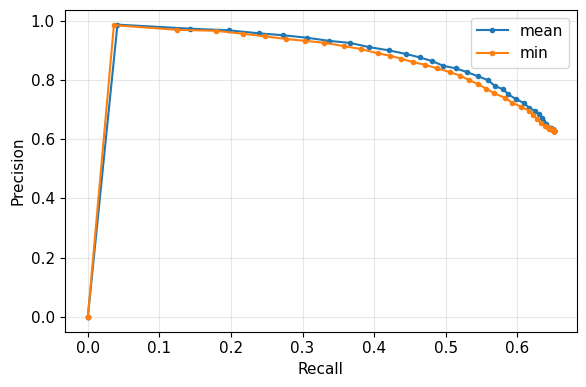

{
  "mean": {
    "threshold": 0.58,
    "f1_micro": 0.6611378338032842,
    "f1_macro": 0.6274772847523815,
    "precision": 0.7677195685670262,
    "recall": 0.5805418001747743
  },
  "min": {
    "threshold": 0.46,
    "f1_micro": 0.6534837015294299,
    "f1_macro": 0.6250243728328153,
    "precision": 0.6957236842105263,
    "recall": 0.6160792309933003
  }
}
Результаты сохранены в artifacts


In [34]:
if '6.5' in BONUS_TASKS:
    threshold_tags, threshold_probs = predict_word_tags(model, val_tokens, return_probs=True)
    thresholds = np.linspace(0, 1, 51)
    threshold_curves = {}
    best_thresholds = {}
    for aggregation in ['mean', 'min']:
        curve = []
        for threshold in thresholds:
            filtered = []
            for tags, probs in zip(threshold_tags, threshold_probs):
                kept = []
                for start, end, entity_type in bio_to_spans(tags):
                    values = probs[start:end]
                    confidence = float(np.mean(values)) if aggregation == 'mean' else min(values)
                    if confidence >= threshold:
                        kept.append((start, end, entity_type))
                filtered.append(spans_to_bio(kept, len(tags)))
            curve.append({'threshold': float(threshold), **entity_scores(val_gold, filtered)})
        assert all(b['recall'] <= a['recall'] + 1e-12 for a, b in zip(curve, curve[1:]))
        best = max(curve, key=lambda row: (row['f1_micro'], -row['threshold']))
        threshold_curves[aggregation] = curve
        best_thresholds[aggregation] = best
    bonus_results['6.5'] = {'selection_split': 'validation', 'best': best_thresholds, 'curves': threshold_curves}
    fig, ax = plt.subplots(figsize=(6, 4))
    for aggregation, curve in threshold_curves.items():
        ax.plot([r['recall'] for r in curve], [r['precision'] for r in curve], '.-', label=aggregation)
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(json.dumps(best_thresholds, ensure_ascii=False, indent=2))

(ARTIFACTS / 'bonuses.json').write_text(json.dumps(json_ready(bonus_results), ensure_ascii=False, indent=2), encoding='utf-8')
analysis_details = dict(dataset_revision=DATASET_REVISION, source_sizes=source_sizes, duplicate_counts=duplicate_counts,
                        dataset_stats=dataset_stats, roundtrip=roundtrip_stats, blocks=blocks,
                        shapes={'input_ids': list(out.logits.shape[:2]), 'logits': list(out.logits.shape),
                                'hidden_states': [list(h.shape) for h in out.hidden_states]},
                        truncation=coverage_stats,
                        baseline=baseline, random_tag_counts=random_tag_counts, unknown_fraction=unknown_fraction,
                        history=history, validation=validation, test=final, errors=errors, error_examples=error_examples,
                        ablation=ablation, train_seconds=train_seconds, device=DEVICE_NAME,
                        versions={'python': platform.python_version(), 'torch': torch.__version__,
                                  'transformers': transformers.__version__, 'datasets': datasets.__version__})
(ARTIFACTS / 'analysis.json').write_text(json.dumps(json_ready(analysis_details), ensure_ascii=False, indent=2), encoding='utf-8')
(ARTIFACTS / 'training_history.json').write_text(json.dumps(json_ready({'main': history, 'freeze': ablation_history}), indent=2), encoding='utf-8')
print('Результаты сохранены в artifacts')


**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Для средней уверенности лучший порог равен 0,58, validation F1 0,661, прибавка к порогу 0 составляет 0,023  
Для минимальной уверенности лучший порог равен 0,46, validation F1 0,653, прибавка 0,015

Среднее допускает одно слабое слово внутри уверенного спана, минимум отбрасывает весь спан из-за самого неуверенного слова и поэтому сильнее зависит от его длины  
Повышение порога только удаляет предсказанные спаны и не создает новые верные, поэтому recall не растет, это дополнительно проверено для всей сетки  
Порог подобран на validation и test повторно не оценивался, найденная прибавка требует проверки на новых данных  
